# Figure 6 — Deployment schematic: regime-routed model selection
iMeta-style closing schematic: the protocol measures the observable regime
(obs_agreement, perturbation density) at prediction time and routes model
choice accordingly — the paper's actionable contribution in one panel.

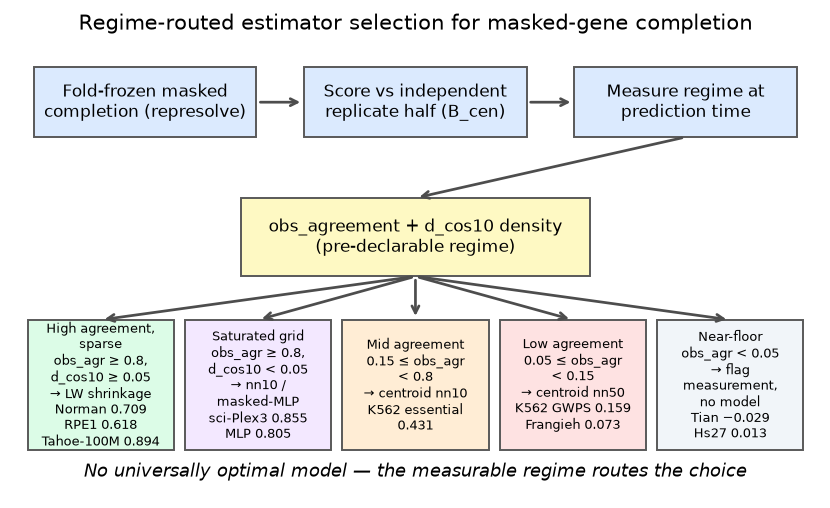

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RES = os.path.join("..", "..", "results")
FIG = os.path.join("..", "..", "figures")
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300,
                     "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
MODELS = ["lw", "svd20", "moppca5", "nn10", "nn50"]
MODEL_LABELS = {"lw": "LW shrinkage", "svd20": "SVD-20",
                "moppca5": "moPPCA-5", "nn10": "nn10",
                "nn50": "nn50"}
CONTEXTS = [
    ("K562 essential", "j22_k562_foldfrozen_centroid.csv"),
    ("K562 GWPS", "j22_k562_gwps_foldfrozen_centroid.csv"),
    ("Norman", "j49_norman_foldfrozen.csv"),
    ("RPE1", "j49_rpe1_foldfrozen.csv"),
    ("sci-Plex3", "j49_sciplex3.csv"),
    ("Frangieh", "j78_frangieh_merged.csv"),
    ("Tian CRISPRi", "j78_tian2021i_merged.csv"),
    ("RPE1 E150", "j78_rpe1e150_merged.csv"),
    ("Tahoe-100M", "j78_tahoe_merged.csv"),
]
def load_ctx(name, fname):
    df = pd.read_csv(os.path.join(RES, fname))
    df["context"] = name
    return df

fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.axis("off")

def box(x, y, w, h, txt, fc, fs=8.5, tc="black"):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec="0.35"))
    ax.text(x + w/2, y + h/2, txt, ha="center", va="center",
            fontsize=fs, color=tc)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="0.3", lw=1.4))

# protocol spine (top)
box(0.02, 0.78, 0.28, 0.16, "Fold-frozen masked\ncompletion (represolve)", "#dbeafe")
box(0.36, 0.78, 0.28, 0.16, "Score vs independent\nreplicate half (B_cen)", "#dbeafe")
box(0.70, 0.78, 0.28, 0.16, "Measure regime at\nprediction time", "#dbeafe")
arrow(0.30, 0.86, 0.36, 0.86); arrow(0.64, 0.86, 0.70, 0.86)

# regime router (middle)
box(0.28, 0.46, 0.44, 0.18,
    "obs_agreement + d_cos10 density\n(pre-declarable regime)", "#fef9c3")
arrow(0.84, 0.78, 0.50, 0.64)

# five routing outcomes (bottom), matching Table 3 thresholds
bw = 0.184; xs = [0.012, 0.210, 0.408, 0.606, 0.804]
box(xs[0], 0.06, bw, 0.30,
    "High agreement,\nsparse\nobs_agr ≥ 0.8,\nd_cos10 ≥ 0.05\n→ LW shrinkage\nNorman 0.709\nRPE1 0.618\nTahoe-100M 0.894", "#dcfce7", fs=6.6)
box(xs[1], 0.06, bw, 0.30,
    "Saturated grid\nobs_agr ≥ 0.8,\nd_cos10 < 0.05\n→ nn10 /\nmasked-MLP\nsci-Plex3 0.855\nMLP 0.805", "#f3e8ff", fs=6.6)
box(xs[2], 0.06, bw, 0.30,
    "Mid agreement\n0.15 ≤ obs_agr\n< 0.8\n→ centroid nn10\nK562 essential\n0.431", "#ffedd5", fs=6.6)
box(xs[3], 0.06, bw, 0.30,
    "Low agreement\n0.05 ≤ obs_agr\n< 0.15\n→ centroid nn50\nK562 GWPS 0.159\nFrangieh 0.073", "#fee2e2", fs=6.6)
box(xs[4], 0.06, bw, 0.30,
    "Near-floor\nobs_agr < 0.05\n→ flag\nmeasurement,\nno model\nTian −0.029\nHs27 0.013", "#f1f5f9", fs=6.6)
for x in xs:
    arrow(0.50, 0.46, x + bw/2, 0.36)
ax.text(0.5, 0.0, "No universally optimal model — the measurable regime routes the choice",
        ha="center", fontsize=9.5, style="italic")
ax.set_title("Regime-routed estimator selection for masked-gene completion",
             fontsize=11)
ax.set_xlim(-0.02, 1.04); ax.set_ylim(-0.04, 1.0)
fig.savefig(os.path.join(FIG, "fig6_decision_schematic.png"), bbox_inches="tight")
plt.show()



